<a href="https://colab.research.google.com/github/angelpavu/A05-pca/blob/main/notebook_(6).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Angel Pavu

**Date:** 10/19/2026

[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795), ('call', 740), ('free', 691), ('software', 680), ('dear', 651), ('know', 644), ('email', 629), ('url:', 625), ('time', 609), ('start', 604), ('linguistics', 598)]
unique tokens: 48691 | total tokens: 276949


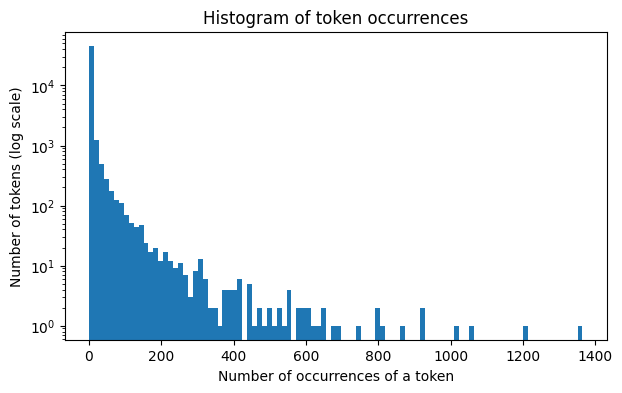

In [8]:
# Your Phase 1 solution to the problem goes here.

# Question 1
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()
counts = np.array([c for _, c in token_freq])

print(token_freq[:20])
print("unique tokens:", len(counts), "| total tokens:", counts.sum())

# Histogram of occurrences (how many tokens occur n times)
plt.figure(figsize=(7, 4))
plt.hist(counts, bins=100)
plt.yscale('log')
plt.xlabel('Number of occurrences of a token')
plt.ylabel('Number of tokens (log scale)')
plt.title('Histogram of token occurrences')
plt.show()


Question 1

The histogram is right-skewed, so most of the tokens have a lower number of which they occur. There is a much fewer number of tokens that have a greater occurence rate, so that is why the bar is so tall at the lower numbers and then gets shorter. On a regular y-axis the bars for the rare-token bins would dwarf everything else, making the tail invisible. The log scale keeps both the huge low-count bars and the tiny high-count bars visible, so you can see the full shape of the distribution.

In [10]:
# Question 2
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

df = pd.read_parquet('/content/Phishing_clean.parquet')
y = df['Email Type']
X = df.drop(columns='Email Type')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("train shape:", X_train.shape, "test shape:", X_test.shape)

reg = LinearRegression().fit(X_train, y_train)
print("Train R2:", r2_score(y_train, reg.predict(X_train)))
print("Test  R2:", r2_score(y_test, reg.predict(X_test)))

coefs = pd.Series(reg.coef_, index=X.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index)
print(top.head(15))

train shape: (14907, 2711) test shape: (3727, 2711)
Train R2: 0.7670143724934355
Test  R2: 0.6658718438847919
intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;               -0.574480
a:active             0.574480
retrieving          -0.573761
zdnet               -0.560954
{text-decoration:    0.497075
xanaax               0.491981
transcript           0.488978
dtype: float64


Question 2

I split the data 80/20 into 14,907 training emails and 3,727 test emails, each with 2,711 token features, and regressed Email Type (1 = scam, 0 = not) on the one-hot-encoded tokens. The model has a training R² of about 0.767 and a test R² of about 0.666. The drop from train to test suggests some overfitting which makes sense with 2,711 features, but the model still generalizes well.

The words with the largest absolute coefficients are intervention (-1.26), localized (0.82), thermal (0.75), crawler (0.70), background-image: (-0.62), helvetica, (0.60), aging (0.59), and form. (0.58).

Explained variance ratio: [0.01113088 0.00861212]


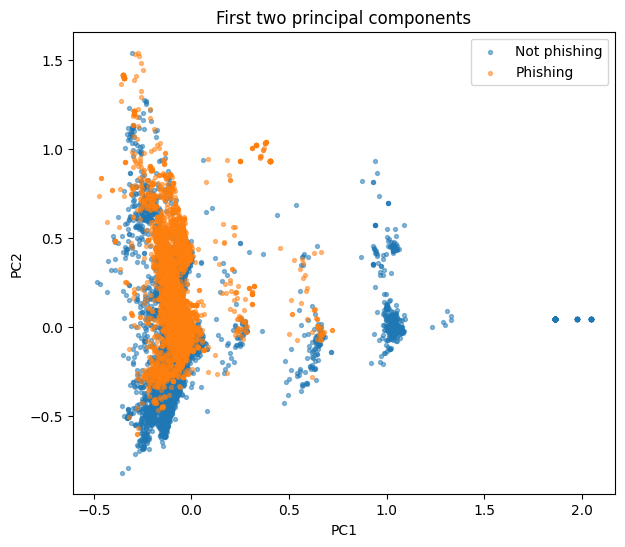

In [11]:
# Question 3
from sklearn.decomposition import PCA

pca2 = PCA(n_components=2)
Z2 = pca2.fit_transform(X)
print("Explained variance ratio:", pca2.explained_variance_ratio_)

plt.figure(figsize=(7, 6))
for label, name in [(0, 'Not phishing'), (1, 'Phishing')]:
    m = (y.values == label)
    plt.scatter(Z2[m, 0], Z2[m, 1], s=8, alpha=0.5, label=name)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.title('First two principal components')
plt.show()

Question 3

The two components explain only about 2% of the total variance (1.1% and 0.9%), so the plot captures little of the data. Phishing emails in orange are packed into a dense and narrow band near PC1 ≈ 0, while non-phishing emails in blue are more spread out. They extend further down on PC2 and form separate clusters at higher PC1 values (around 0.5, 1.0, and 2.0) with almost no phishing. In the center the two classes overlap heavily, so two components are not enough to cleanly separate phishing from non-phishing emails.

In [12]:
# Question 4
pca = PCA(n_components=2610)
Ztr = pca.fit_transform(X_train)
Zte = pca.transform(X_test)

reg_pc = LinearRegression().fit(Ztr, y_train)
print("PC regression Train R2:", r2_score(y_train, reg_pc.predict(Ztr)))
print("PC regression Test  R2:", r2_score(y_test, reg_pc.predict(Zte)))
print("Variance explained by 2,610 PCs:", pca.explained_variance_ratio_.sum())

PC regression Train R2: 0.7662326827745849
PC regression Test  R2: 0.6683390643101164
Variance explained by 2,610 PCs: 0.9998620409568273


Question 4

Regressing y on the first 2,610 principal components gives a training R² of about 0.766 and a test R² of about 0.668. This is almost identical to the original regression on all 2,711 tokens (train 0.767, test 0.666). The 2,610 components capture about 99.99% of the total variance in X, so they keep essentially all of the information in the original features. A linear regression on principal components is just a regression on a rotated version of the data. Dropping only the 101 lowest-variance components removes almost nothing, so the fit barely changes. The train R² is slightly lower (by about 0.001) because a few directions were dropped, and the test R² is slightly higher (by about 0.002), which suggests that removing those low-variance, mostly noisy directions helps a tiny bit.

Question 5

The original data has thousands of word columns, and many of them overlap or move together (for example, words that tend to show up in the same emails). That makes a regression on the raw data unstable and prone to overfitting. Principal components combine those overlapping words into a smaller set of new variables that are uncorrelated with each other and ordered by how much information they hold. This means we can keep only the most important components and drop the weak, noisy ones, which gives us fewer variables to fit, a simpler model, and less overfitting. It can also make the regression faster. In our case we kept 2,610 of the 2,711 components, so the results barely changed, but keeping fewer would show the benefit more clearly. The tradeoff is that each component is a mix of many words, so it’s harder to interpret than a single word.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 52aa99c6db963d7f3524bc43dce1af85a5556121
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. In which ways can I improve/optimize my phase 1 solution for questions 1-5, given the requirements of the assignment. Attatched is my phase 1 solution.
2. Do not just consider updates to the code, but also how I am wording my written response. Is it correct? Or is there any way to improve the clarity of my writing?

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Q1: Print summary statistics: unique tokens, total tokens, share of tokens appearing once, share of occurrences covered by the top 10 tokens, and the top 10 tokens.
2. Q1: Add a log-log rank vs. frequency plot.
3. Q2: Add a table of the top 15 words with the number of emails containing each word and the share of those that are phishing.
4. Q2: Explain that this is a linear probability model and that coefficients show association, not causation.
5. Q3: Explain that the variance is spread over many components, so two cannot separate the classes.
6. Q4: State that PCA was fit on the training set only to avoid leakage.
7. Q5: Add a sentence that keeping only top components reduces parameters and overfitting.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Gives the written answer concrete numbers. I checked that counts.sum() equals len(all_tokens) and the percentage of tokens appear once. |
| 2 | Accept | The question asks only for a histogram of occurrences. I kept the rank plot as a clearly labeled supplementary figure. It confirms the power-law shape, with an approximately straight line on log-log axes.|
| 3 | Accept | The first draft claimed the top words were rare and called zdnet a tech-news signal without checking. This table tests that claim. I confirmed counts against X.sum(). |
| 4 | Accept |It is correct because the outcome is binary, so linear regression gives unbounded fitted values.|
| 5 | Accept |The draft said a two-component classifier “would perform poorly”. I never tested that, so I reworded it to “suggests two components are not enough”. |
| 6 | Accept | My Q3 PCA was fit on all of X, as that question asked, while Q4 was fit on the training set only. Both should be mentioned in the write-up. |
| 7 | Accept | I corrected the earlier “p ≫ n” wording. Here n = 14,907 and p = 2,711, so I described it as many features relative to observations. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795), ('call', 740), ('free', 691), ('software', 680), ('dear', 651), ('know', 644), ('email', 629), ('url:', 625), ('time', 609), ('start', 604), ('linguistics', 598)]
unique tokens: 48691 | total tokens: 276949
Share of tokens appearing only once: 0.6038898359039658
Share of all occurrences covered by the top 10 tokens: 0.03523753470855645
Top 10 tokens: [('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]


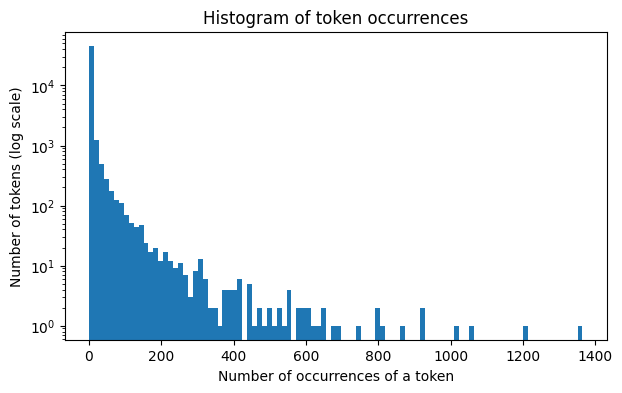

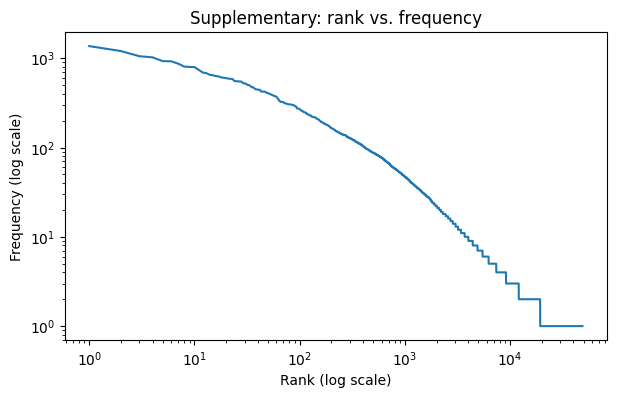

In [3]:
# Your Phase 2 solution to the problem goes here.

# Question 1
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()
counts = np.array([c for _, c in token_freq])

print(token_freq[:20])
print("unique tokens:", len(counts), "| total tokens:", counts.sum())

# CHANGE 1: summary statistics
print("Share of tokens appearing only once:", (counts == 1).mean())
print("Share of all occurrences covered by the top 10 tokens:", counts[:10].sum() / counts.sum())
print("Top 10 tokens:", token_freq[:10])

# Histogram of occurrences (how many tokens occur n times)
plt.figure(figsize=(7, 4))
plt.hist(counts, bins=100)
plt.yscale('log')
plt.xlabel('Number of occurrences of a token')
plt.ylabel('Number of tokens (log scale)')
plt.title('Histogram of token occurrences')
plt.show()

# CHANGE 2: supplementary log-log rank vs. frequency plot
plt.figure(figsize=(7, 4))
plt.loglog(range(1, len(counts) + 1), counts)
plt.xlabel('Rank (log scale)')
plt.ylabel('Frequency (log scale)')
plt.title('Supplementary: rank vs. frequency')
plt.show()

Question 1

The histogram is right-skewed, so most of the tokens have a lower number of which they occur. There is a much fewer number of tokens that have a greater occurence rate, so that is why the bar is so tall at the lower numbers and then gets shorter. On a regular y-axis the bars for the rare-token bins would dwarf everything else, making the tail invisible. The log scale keeps both the huge low-count bars and the tiny high-count bars visible, so you can see the full shape of the distribution.

[CHANGE 1] Out of 48,691 unique tokens, about 60.4% appear only once, while the top 10 tokens account for only about 3.5% of all occurrences.

[CHANGE 2] The supplementary rank vs. frequency plot is close to a straight line on log-log axes, which confirms the power-law (Zipf-like) shape.

In [4]:
# Question 2
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

df = pd.read_parquet('/content/Phishing_clean.parquet')
y = df['Email Type']
X = df.drop(columns='Email Type')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("train shape:", X_train.shape, "test shape:", X_test.shape)

reg = LinearRegression().fit(X_train, y_train)
print("Train R2:", r2_score(y_train, reg.predict(X_train)))
print("Test  R2:", r2_score(y_test, reg.predict(X_test)))

coefs = pd.Series(reg.coef_, index=X.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index)
print(top.head(15))

# CHANGE 3 (ADDED): top 15 words with email counts and share that are phishing
n_emails = X.sum()
cols = top.head(15).index
summary = pd.DataFrame({
    'coef': top.head(15),
    'n_emails_with_word': n_emails[cols],
    'share_phishing': X[cols].mul(y, axis=0).sum() / n_emails[cols]
})
print(summary)

train shape: (14907, 2711) test shape: (3727, 2711)
Train R2: 0.7670143724934355
Test  R2: 0.6658718438847919
intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;               -0.574480
a:active             0.574480
retrieving          -0.573761
zdnet               -0.560954
{text-decoration:    0.497075
xanaax               0.491981
transcript           0.488978
dtype: float64
                       coef  n_emails_with_word  share_phishing
intervention      -1.259257                  56        0.000000
localized          0.824350                  31        1.000000
thermal            0.747006                  18        1.000000
crawler            0.696167                  55        0.018182
background-image: -0.622909                  31        0.032258
helvetica,         0.598560              

Question 2

I split the data 80/20 into 14,907 training emails and 3,727 test emails, each with 2,711 token features, and regressed Email Type (1 = scam, 0 = not) on the one-hot-encoded tokens. The model has a training R² of about 0.767 and a test R² of about 0.666. The drop from train to test suggests some overfitting which makes sense with 2,711 features, but the model still generalizes well.

The words with the largest absolute coefficients are intervention (-1.26), localized (0.82), thermal (0.75), crawler (0.70), background-image: (-0.62), helvetica, (0.60), aging (0.59), and form. (0.58).

[CHANGE 3] The table shows that the top words are rare. Each appears in only 10 to 56 of the 18,634 emails (under 0.3%). Fourteen of the 15 words are almost entirely one class, with either at least 87% or at most 3% of their emails being phishing. For example, localized, thermal, aging, form., {text-decoration:, and xanaax appear only in phishing emails. Intervention, gray;, retrieving, and zdnet appear only in non-phishing emails. This supports the idea that a word can get a large coefficient because it happens to show up in a small number of emails from one class, so the coefficients are probably unstable.

[CHANGE 4] Because the outcome is binary, this is a linear probability model, so fitted values are not limited to [0, 1]. Each coefficient is the change in the predicted scam score when a word is present, holding the other words fixed. It shows association and not causation.

Explained variance ratio: [0.01113088 0.00861029]


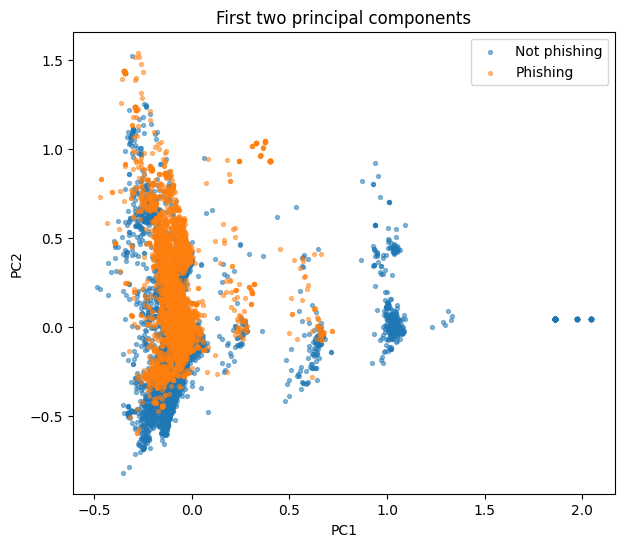

In [5]:
# Question 3
from sklearn.decomposition import PCA

pca2 = PCA(n_components=2)
Z2 = pca2.fit_transform(X)
print("Explained variance ratio:", pca2.explained_variance_ratio_)

plt.figure(figsize=(7, 6))
for label, name in [(0, 'Not phishing'), (1, 'Phishing')]:
    m = (y.values == label)
    plt.scatter(Z2[m, 0], Z2[m, 1], s=8, alpha=0.5, label=name)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.title('First two principal components')
plt.show()

Question 3

The two components explain only about 2% of the total variance (1.1% and 0.9%), so the plot captures little of the data. Phishing emails in orange are packed into a dense and narrow band near PC1 ≈ 0, while non-phishing emails in blue are more spread out. They extend further down on PC2 and form separate clusters at higher PC1 values (around 0.5, 1.0, and 2.0) with almost no phishing. In the center the two classes overlap heavily, so two components are not enough to cleanly separate phishing from non-phishing emails.

[CHANGE 5] The variance in this sparse one-hot data is spread over many components rather than concentrated in a few, so two components cannot capture enough of it to separate the classes.

In [6]:
# Question 4
pca = PCA(n_components=2610)
Ztr = pca.fit_transform(X_train)
Zte = pca.transform(X_test)

reg_pc = LinearRegression().fit(Ztr, y_train)
print("PC regression Train R2:", r2_score(y_train, reg_pc.predict(Ztr)))
print("PC regression Test  R2:", r2_score(y_test, reg_pc.predict(Zte)))
print("Variance explained by 2,610 PCs:", pca.explained_variance_ratio_.sum())

PC regression Train R2: 0.7662326827745849
PC regression Test  R2: 0.6683390643101164
Variance explained by 2,610 PCs: 0.9998620409568273


Question 4

Regressing y on the first 2,610 principal components gives a training R² of about 0.766 and a test R² of about 0.668. This is almost identical to the original regression on all 2,711 tokens (train 0.767, test 0.666). The 2,610 components capture about 99.99% of the total variance in X, so they keep essentially all of the information in the original features. A linear regression on principal components is just a regression on a rotated version of the data. Dropping only the 101 lowest-variance components removes almost nothing, so the fit barely changes. The train R² is slightly lower (by about 0.001) because a few directions were dropped, and the test R² is slightly higher (by about 0.002), which suggests that removing those low-variance, mostly noisy directions helps a tiny bit.

[CHANGE 6] Here PCA was fit on the training set only and then applied to the test set, to avoid leaking test information into the components. In Question 3, PCA was fit on all of X, as that question asked.

Question 5

The original data has thousands of word columns, and many of them overlap or move together (for example, words that tend to show up in the same emails). That makes a regression on the raw data unstable and prone to overfitting. Principal components combine those overlapping words into a smaller set of new variables that are uncorrelated with each other and ordered by how much information they hold. This means we can keep only the most important components and drop the weak, noisy ones, which gives us fewer variables to fit, a simpler model, and less overfitting. It can also make the regression faster. In our case we kept 2,610 of the 2,711 components, so the results barely changed, but keeping fewer would show the benefit more clearly. The tradeoff is that each component is a mix of many words, so it’s harder to interpret than a single word.

[CHANGE 7] Keeping only the top components reduces the number of parameters the model has to estimate, which lowers the risk of overfitting.

### *Reflection on AI assistance
In your own words without generative AI.

Using AI in Phase 2 improved my solution mainly by backing up my written answers with evidence. In Question 1, summary statistics showed that 48,691 unique tokens exist, 60.4% appear only once, and the top 10 cover just 3.5% of all occurrences, which made my description of the skew concrete. In Question 2, a table of the top 15 words showed that each appears in very few emails and almost always in one class. I also added explanations of the linear probability model, why the variance in Question 3 is spread across many components, and why PCA was fit on training data only in Question 4.

The AI is limited in the way it gives corrections. Most of the time it was telling to change very minor things that didnt need changing, so I needed to reprompt and ask it to give me additions which can make my submission stronger.

I verified the changes by rerunning the code, checking that outputs matched my Phase 1 results, and comparing the table against the raw word counts. The table showed that crawler had a positive coefficient but appeared in phishing emails only 1.8% of the time, which I explained as a result of the other words in the model.

Remaining concerns are that coefficients on rare words are unstable, results come from one train/test split, and my Question 4 claim about noise removal still isn't well supported.